ACTIVIDAD FUNDAMENTAL 2

Equipo:

Cristofer Jair Zuñiga Escobar 2189229

Leonardo Alfredo López Reyes 2181755

Diego Otoniel Cantu Cantu 2208782

Angel Gabriel Alonso Navarro 2116170

Alexis Eduardo Puente Mendoza 2188873

In [17]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

In [36]:
url = "https://archive.ics.uci.edu/ml/machine-learning-databases/wine-quality/winequality-red.csv"
df = pd.read_csv(url, sep=';')
# Muestra las primeras 5 filas y el resumen estadístico.
print(df.head())
print(df.describe())

   fixed acidity  volatile acidity  citric acid  residual sugar  chlorides  \
0            7.4              0.70         0.00             1.9      0.076   
1            7.8              0.88         0.00             2.6      0.098   
2            7.8              0.76         0.04             2.3      0.092   
3           11.2              0.28         0.56             1.9      0.075   
4            7.4              0.70         0.00             1.9      0.076   

   free sulfur dioxide  total sulfur dioxide  density    pH  sulphates  \
0                 11.0                  34.0   0.9978  3.51       0.56   
1                 25.0                  67.0   0.9968  3.20       0.68   
2                 15.0                  54.0   0.9970  3.26       0.65   
3                 17.0                  60.0   0.9980  3.16       0.58   
4                 11.0                  34.0   0.9978  3.51       0.56   

   alcohol  quality  
0      9.4        5  
1      9.8        5  
2      9.8        5 

In [37]:
# Identifica si existen valores nulos y elimínalos.
print(df.isnull().sum())

fixed acidity           0
volatile acidity        0
citric acid             0
residual sugar          0
chlorides               0
free sulfur dioxide     0
total sulfur dioxide    0
density                 0
pH                      0
sulphates               0
alcohol                 0
quality                 0
dtype: int64


In [38]:
# Eliminación de datos nulos
df = df.dropna()
print(f"Filas restantes de la eliminación de valores nulos: {df.shape[0]}")

Filas restantes de la eliminación de valores nulos: 1599


In [39]:
# Crea una nueva columna llamada is_good que sea 1 si la quality es mayor a 6, y 0 en caso contrario.

df['is_good'] = (df['quality'] > 6).astype(int)

print("\n Valores únicos de la nueva columna:")
print(df['is_good'].value_counts())


 Valores únicos de la nueva columna:
is_good
0    1382
1     217
Name: count, dtype: int64


In [40]:
# Filtra el DataFrame para mostrar solo los vinos con un nivel de alcohol superior al 11%
df_alcholalto = df[df['alcohol'] > 11.0]

print(f"(Total: {df_alcholalto.shape[0]} filas)")
print(df_alcholalto.head())

(Total: 408 filas)
     fixed acidity  volatile acidity  citric acid  residual sugar  chlorides  \
45             4.6              0.52         0.15             2.1      0.054   
95             4.7              0.60         0.17             2.3      0.058   
131            5.6              0.50         0.09             2.3      0.049   
132            5.6              0.50         0.09             2.3      0.049   
142            5.2              0.34         0.00             1.8      0.050   

     free sulfur dioxide  total sulfur dioxide  density    pH  sulphates  \
45                   8.0                  65.0   0.9934  3.90       0.56   
95                  17.0                 106.0   0.9932  3.85       0.60   
131                 17.0                  99.0   0.9937  3.63       0.63   
132                 17.0                  99.0   0.9937  3.63       0.63   
142                 27.0                  63.0   0.9916  3.68       0.79   

     alcohol  quality  is_good  
45      13

### 1.2 Operaciones Matemáticas con NumPy

In [41]:
# Convierte las columnas de características (features) en una matriz de NumPy llamada X.

feactures = [col for col in df.columns if col not in ['quality', 'is_good']]

x = df[feactures].to_numpy()
print(f"Matriz X (filas, columnas): {x.shape}")

Matriz X (filas, columnas): (1599, 11)


In [42]:
# Calcula la media y la desviación estándar de cada columna utilizando únicamente funciones de NumPy (np.mean, np.std).

mu = np.mean(x, axis=0)
sigma = np.std(x, axis=0)

print("La media es: \n", mu)
print("\nLa desviación estándar es: \n", sigma)

La media es: 
 [ 8.31963727  0.52782051  0.27097561  2.5388055   0.08746654 15.87492183
 46.46779237  0.99674668  3.3111132   0.65814884 10.42298311]

La desviación estándar es: 
 [1.74055180e+00 1.79003704e-01 1.94740214e-01 1.40948711e+00
 4.70505826e-02 1.04568856e+01 3.28850367e+01 1.88674370e-03
 1.54338181e-01 1.69453967e-01 1.06533430e+00]


In [43]:
# Normalización Z-Score: Implementa manualmente la fórmula para normalizar los datos:

x_norm = (x / mu) / sigma
print("\n Información de las primeras 3 columnas:")
print(x_norm[:3])


 Información de las primeras 3 columnas:
[[5.11022915e-01 7.40883218e+00 0.00000000e+00 5.30961536e-01
  1.84674372e+01 6.62641654e-02 2.22499248e-02 5.30573791e+02
  6.86846532e+00 5.02125369e+00 8.46544728e-01]
 [5.38645775e-01 9.31396045e+00 0.00000000e+00 7.26578943e-01
  2.38132743e+01 1.50600376e-01 4.38454400e-02 5.30042048e+02
  6.26184873e+00 6.09723662e+00 8.82567908e-01]
 [5.38645775e-01 8.04387494e+00 7.58008621e-01 6.42742911e-01
  2.23553188e+01 9.03602255e-02 3.53381158e-02 5.30148397e+02
  6.37925839e+00 5.82824089e+00 8.82567908e-01]]


In [10]:
print(f"Dimensiones de X: {x.shape}")


Dimensiones de X: (1599, 11)


### 1.3 Visualización de Insights con Matplotlib

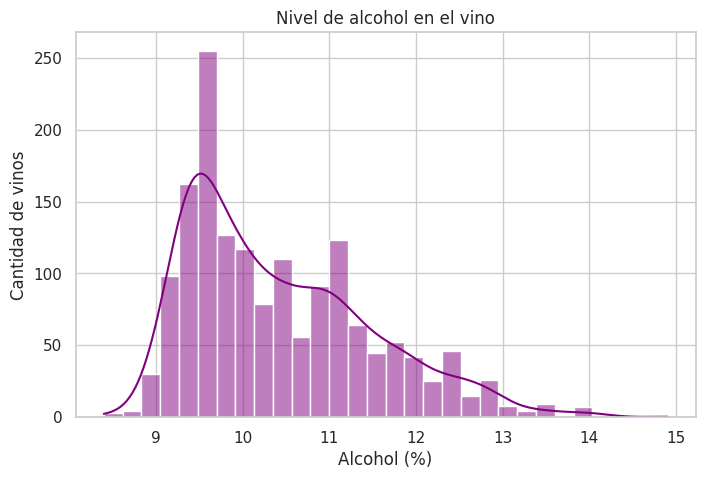

In [18]:
#Histograma: Crea un histograma de la variable alcohol para ver su distribución.

plt.figure(figsize=(8,5))
sns.histplot(df['alcohol'], bins=30, kde=True, color='purple')
plt.title("Nivel de alcohol en el vino")
plt.xlabel("Alcohol (%)")
plt.ylabel("Cantidad de vinos")
plt.show()

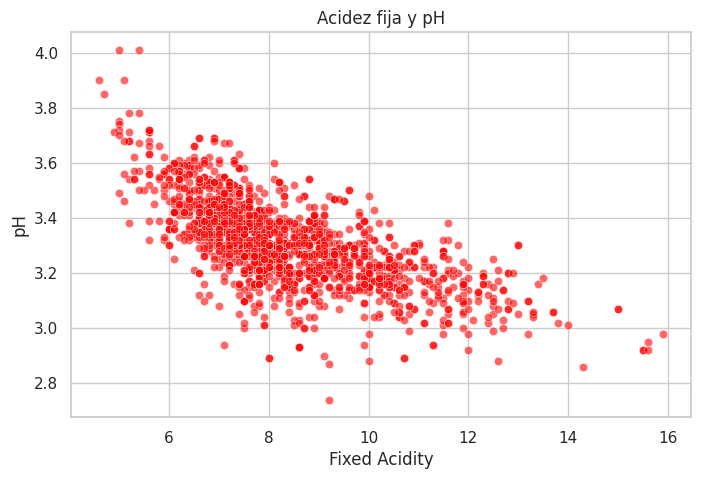

In [19]:
#Scatter Plot: Realiza un gráfico de dispersión entre pH y fixed acidity. ¿Notas alguna tendencia?

plt.figure(figsize=(8,5))
sns.scatterplot(data=df, x='fixed acidity', y = 'pH', alpha=0.6, color='red')

plt.title("Acidez fija y pH")
plt.xlabel('Fixed Acidity')
plt.ylabel("pH")
plt.show()

/tmp/ipykernel_11198/3025902246.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxenplot(data=df, x='quality', y='alcohol', palette='Set2')


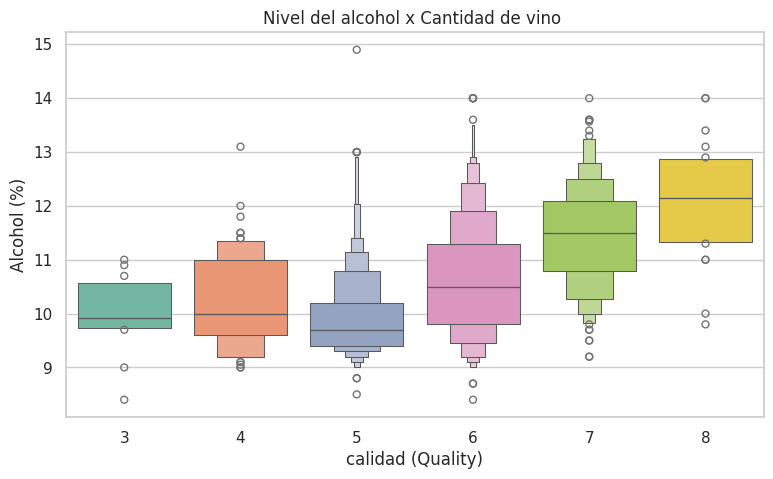

In [20]:
#Boxplot: Genera un gráfico de cajas que compare el nivel de alcohol según la quality.

plt.figure(figsize=(9,5))
sns.boxenplot(data=df, x='quality', y='alcohol', palette='Set2')

plt.title("Nivel del alcohol x Cantidad de vino ")
plt.xlabel('calidad (Quality)')
plt.ylabel('Alcohol (%)')
plt.show()

### 2.1 Análisis exploratorio con Pandas

In [55]:
 #URL del dataset de pingüinos de Palmer
url = "https://raw.githubusercontent.com/mwaskom/seaborn-data/master/penguins.csv"

# Cargar los datos
df = pd.read_csv(url)

# Mostrar los primeros registros para confirmar
print("Dataset cargado correctamente:")

Dataset cargado correctamente:


In [56]:
# Limpieza de datos reales (que suelen venir con errores o huecos)
print("Valores nulos por columna: ")
print(df.isnull().sum())

filas_nulos = df[df.isnull().any(axis=1)]
print(f"\nTotal de filas con al menos un NaN: {len(filas_nulos)}")

Valores nulos por columna: 
species               0
island                0
bill_length_mm        2
bill_depth_mm         2
flipper_length_mm     2
body_mass_g           2
sex                  11
dtype: int64

Total de filas con al menos un NaN: 11


In [57]:
# Calcula la masa corporal promedio por cada especie y por isla

masa_prom = df.groupby(['species', 'island'])['body_mass_g'].mean().reset_index()

masa_prom = masa_prom.rename(columns={'body_massg': 'mean_body_mass_g'})

print("Masa corporal promedio por especie e isla: ")
print(masa_prom)

Masa corporal promedio por especie e isla: 
     species     island  body_mass_g
0     Adelie     Biscoe  3709.659091
1     Adelie      Dream  3688.392857
2     Adelie  Torgersen  3706.372549
3  Chinstrap      Dream  3733.088235
4     Gentoo     Biscoe  5076.016260


In [58]:
# Crea un subconjunto de datos que solo obtenga a los pingüinos de la especie "Gentoo" que pesen más de 5000g

gentoo = df[(df['species'] == 'Gentoo') & (df['body_mass_g'] > 5000)]

print(f"\nPingüinos que pesan más de 5000g: {len(gentoo)}")
print(f"\n Primeros registros del subconjunto: ")
print(gentoo.head())


Pingüinos que pesan más de 5000g: 61

 Primeros registros del subconjunto: 
    species  island  bill_length_mm  bill_depth_mm  flipper_length_mm  \
221  Gentoo  Biscoe            50.0           16.3              230.0   
223  Gentoo  Biscoe            50.0           15.2              218.0   
224  Gentoo  Biscoe            47.6           14.5              215.0   
227  Gentoo  Biscoe            46.7           15.3              219.0   
229  Gentoo  Biscoe            46.8           15.4              215.0   

     body_mass_g   sex  
221       5700.0  MALE  
223       5700.0  MALE  
224       5400.0  MALE  
227       5200.0  MALE  
229       5150.0  MALE  


### 2.2 Procesamiento de señales con NumPy

In [28]:
#Extrae las columnas bill_length_mm (largo) y bill_depth_mm (alto) y conviértelas en una matriz de NumPy de N X 2
sub_df = df[['bill_length_mm', 'bill_depth_mm']].dropna()

matriz_p = sub_df.to_numpy()
print("Dimensiones de la matriz: ", matriz_p.shape)
print("El tipo de dato que se usa: ", type(matriz_p))
print(matriz_p[:5])


Dimensiones de la matriz:  (342, 2)
El tipo de dato que se usa:  <class 'numpy.ndarray'>
[[39.1 18.7]
 [39.5 17.4]
 [40.3 18. ]
 [36.7 19.3]
 [39.3 20.6]]


In [59]:
# Cálculo de Proporción: Crea un nuevo array que sea el resultado de dividir el largo entre el alto para cada pingüino.

df_clean = df[['bill_length_mm', 'bill_depth_mm']].dropna()

largo = df_clean['bill_length_mm'].to_numpy()
alto = df_clean['bill_depth_mm'].to_numpy()

proporcion_pico = largo / alto

print(f"Total de proporciones calculadas: {len(proporcion_pico)}")
print("Primeras 5 proporciones: ")
print(proporcion_pico[:5])

Total de proporciones calculadas: 342
Primeras 5 proporciones: 
[2.09090909 2.27011494 2.23888889 1.9015544  1.90776699]


In [60]:
# Detección de Outliers: Utiliza una función de NumPy para encontrar qué pingüinos tienen un largo de pico que esté a más de 2 desviaciones estándar de la media del grupo.

largo_p = df['bill_length_mm'].dropna().to_numpy()

media = np.mean(largo_p)
desv = np.std(largo_p)

mascara = np.abs(largo_p - media) > (2 * desv)

outliers = largo_p[mascara]
print(f"Media del largo del pico: {media:.2f} mm")
print(f"Desviación estándar: {desv:.2f} mm")
print(f"Límite inferior: {media - (2 * desv):.2f} mm")
print(f"Límite superior: {media + (2 * desv):.2f} mm")
print(f"\nCantidad de pingüinos considerados outliers: {np.sum(mascara)}")
print("Valores atípicos encontrados:", outliers)

Media del largo del pico: 43.92 mm
Desviación estándar: 5.45 mm
Límite inferior: 33.02 mm
Límite superior: 54.83 mm

Cantidad de pingüinos considerados outliers: 6
Valores atípicos encontrados: [32.1 58.  55.8 59.6 55.9 55.1]


In [61]:
#Slicing: Extrae solo los datos de los pingüinos que están en las posiciones pares del array original.

matriz_compl = df.to_numpy()

matriz_pares = matriz_compl[::2, :]

print(f"Dimensiones de la matriz original: {matriz_compl.shape}")
print(f"Dimensiones de la matriz en posiciones pares: {matriz_pares.shape}")
print("\nPrimeras 5 filas de la matriz en posiciones pares:")
print(matriz_pares[:5])

Dimensiones de la matriz original: (344, 7)
Dimensiones de la matriz en posiciones pares: (172, 7)

Primeras 5 filas de la matriz en posiciones pares:
[['Adelie' 'Torgersen' 39.1 18.7 181.0 3750.0 'MALE']
 ['Adelie' 'Torgersen' 40.3 18.0 195.0 3250.0 'FEMALE']
 ['Adelie' 'Torgersen' 36.7 19.3 193.0 3450.0 'FEMALE']
 ['Adelie' 'Torgersen' 38.9 17.8 181.0 3625.0 'FEMALE']
 ['Adelie' 'Torgersen' 34.1 18.1 193.0 3475.0 nan]]


### 2.3 Visualización científica con Matplotlib

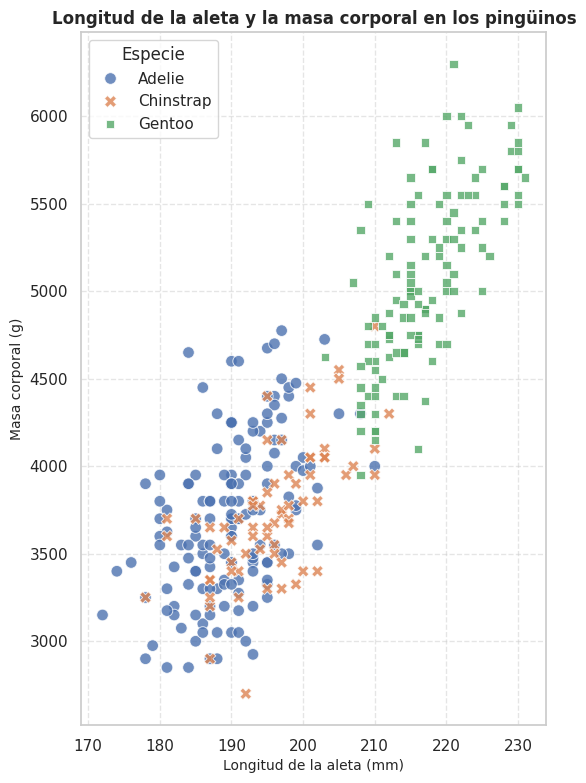

In [62]:
from matplotlib.lines import lineStyles
# Scatter Plot: Grafica flipper_length_mm (aletas) en el eje X y body_mass_g en el eje Y.

plt.figure(figsize=(6,9))

sns.scatterplot(
  data=df,
  x = 'flipper_length_mm',
  y = 'body_mass_g',
  hue = 'species',
  style = 'species',
  palette = 'deep',
  s = 70,
  alpha = 0.8
)

plt.title('Longitud de la aleta y la masa corporal en los pingüinos', fontsize=12, fontweight='bold')

plt.xlabel('Longitud de la aleta (mm)', fontsize=10)
plt.ylabel("Masa corporal (g)", fontsize=10)

plt.legend(title='Especie', loc='upper left')
plt.grid(True, linestyle='--', alpha=0.5)

plt.show()

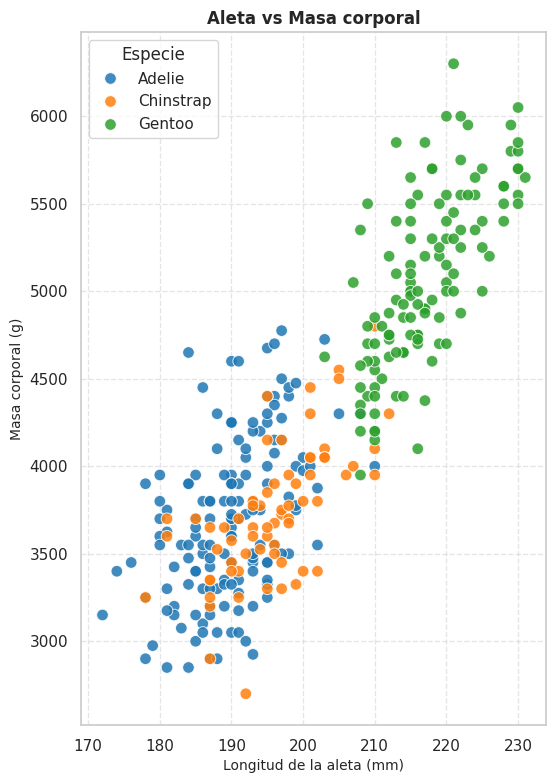

In [63]:
# Codificación de Colores: Usa un color diferente para cada una de las tres especies (Adelie, Chinstrap, Gentoo). Esto ayudará a ver cómo se agrupan naturalmente.

colores_especies = {
  'Adelie':  '#1f77b4',
  'Chinstrap': '#ff7f0e',
  'Gentoo': '#2ca02c'
}

plt.figure(figsize=(6,9))

sns.scatterplot(
 data=df,
 x='flipper_length_mm',
 y = 'body_mass_g',
 hue = 'species',
 palette=colores_especies,
 s = 70,
 alpha= 0.85
)
plt.title('Aleta vs Masa corporal', fontsize=12, fontweight='bold')
plt.xlabel('Longitud de la aleta (mm)', fontsize=10)
plt.ylabel("Masa corporal (g)", fontsize=10)

plt.legend(title='Especie', loc='upper left', frameon=True)
plt.grid(True, linestyle='--', alpha=0.5)

plt.show()

Pingüino más pesado: Especie Gentoo, peso: 6300.0g


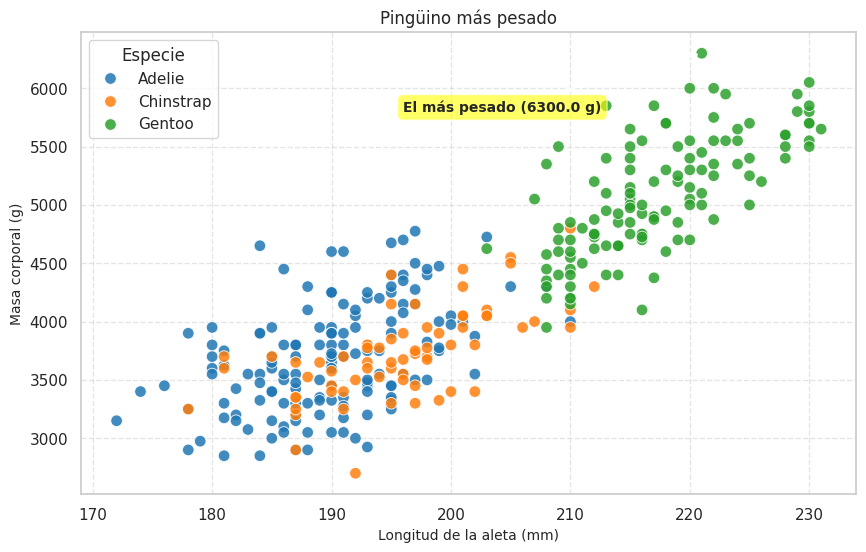

In [64]:
# Anotaciones: Añade una flecha o un texto en el gráfico señalando al pingüino más pesado del dataset.

idx_max_ms = df['body_mass_g'].idxmax()
pinguino_pesado = df.loc[idx_max_ms]

x_val = pinguino_pesado['flipper_length_mm']
y_val = pinguino_pesado['body_mass_g']

print(f"Pingüino más pesado: Especie {pinguino_pesado['species']}, peso: {y_val}g")

plt.figure(figsize=(10,6))

colores_especies = {
  'Adelie': '#1f77b4',
  'Chinstrap': '#ff7f0e',
  'Gentoo': '#2ca02c'
}
sns.scatterplot(
    data=df,
    x='flipper_length_mm',
    y='body_mass_g',
    hue='species',
    palette=colores_especies,
    s=70,
    alpha=0.85
)
plt.annotate(
 f"El más pesado ({y_val} g)",
 xy=(x_val, y_val),
 xytext=(x_val - 25, y_val - 500),
 arrowprops=dict(
   facecolor="black",
   arrowstyle='->',
    lw=1.5
 ),

fontsize=10,
fontweight='bold',
bbox=dict(boxstyle='round,pad=0.4', fc='yellow', alpha=0.6)
)

plt.title('Pingüino más pesado')
plt.xlabel('Longitud de la aleta (mm)', fontsize=10)
plt.ylabel('Masa corporal (g)', fontsize=10)
plt.legend(title='Especie', loc='upper left', frameon=True)
plt.grid(True, linestyle='--', alpha=0.5)

plt.show()

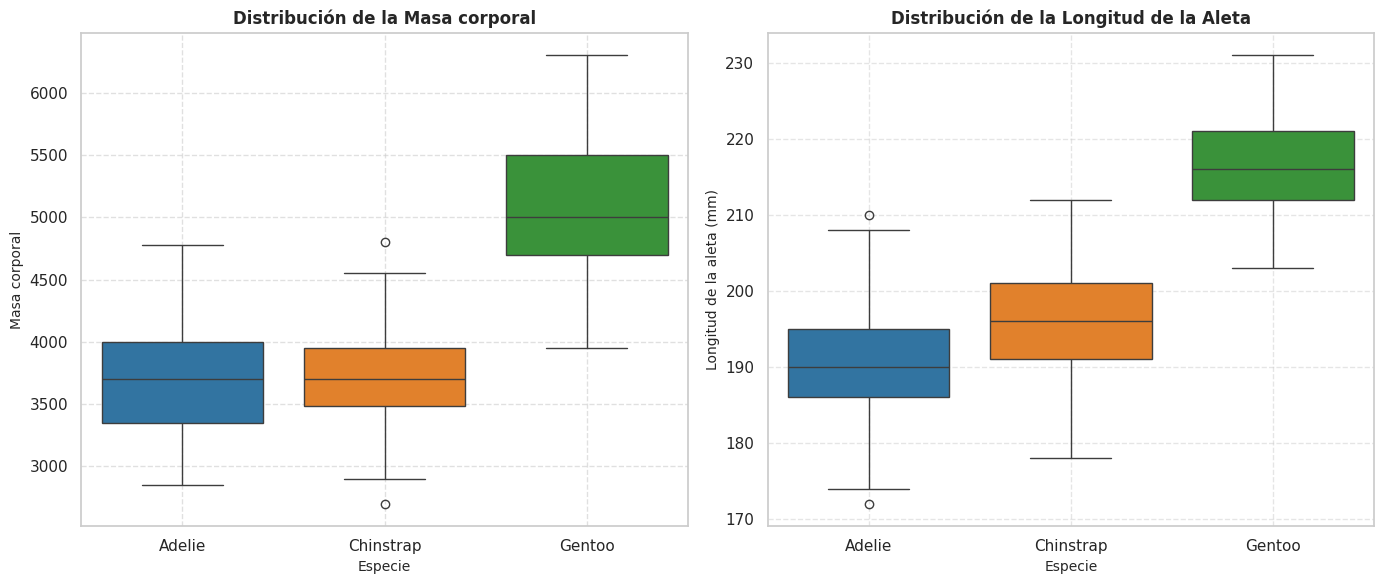

In [65]:
# Crea una figura con dos "subplots" (gráficos uno al lado del otro): uno con la masa corporal y otro con el tamaño de las aletas.
fig, axes = plt.subplots(1, 2,  figsize=(14,6))

colores_especies = {
    'Adelie': '#1f77b4',
    'Chinstrap': '#ff7f0e',
    'Gentoo': '#2ca02c'
}

sns.boxplot(
  data=df,
  x = 'species',
  y = 'body_mass_g',
  hue = 'species',
  palette=colores_especies,
  ax= axes[0]
)

axes[0].set_title('Distribución de la Masa corporal', fontsize=12, fontweight='bold')
axes[0].set_xlabel('Especie', fontsize=10)
axes[0].set_ylabel('Masa corporal', fontsize=10)
axes[0].grid(True, linestyle='--', alpha=0.6)

sns.boxplot(
    data=df,
    x='species',
    y='flipper_length_mm',
    hue='species',
    palette=colores_especies,
    ax=axes[1]
)
axes[1].set_title('Distribución de la Longitud de la Aleta', fontsize=12, fontweight='bold')
axes[1].set_xlabel('Especie', fontsize=10)
axes[1].set_ylabel('Longitud de la aleta (mm)', fontsize=10)
axes[1].grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()

plt.show()